# Спринт 3 - Проект модуля - нейросеть для классификации таблеток

--
В связи с недостуностью ВМ от Яндекс.Практикум, проект выполнен на собственном локальном компьютере без GPU

## Инициалиация

In [ ]:
import random
import pandas as pd
import numpy as np
import pathlib as path
import torch

SEED = 43

# пути
DATASET_PATH = path.Path('data/dataset')
DATASET_PATH.mkdir(parents=True, exist_ok=True)

PREPROCESSING_PATH = path.Path('data/preprocessing')
PREPROCESSING_PATH.mkdir(parents=True, exist_ok=True)

MODELS_PATH = path.Path('data/models')
MODELS_PATH.mkdir(parents=True, exist_ok=True)

def init_random():
    """
    Инициализация случайных величин для повторяемости экспериментов
    """   
    torch.random.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)


## Этап 0 - подготовка
см. [readme.md](readme.md) для установки python и зависимостей

## Этап 1 - загрузка и подготовка данных

- Загрузить датасеты для обучения и валидации, определить операции предобработки, подготовить загрузчики `train_loader` и `val_loader`
- Вывести количество классов и изображений в каждом датасете

### Загрузка датасета

Загрузить архив по предоставленной ссылке на Яндекс Диск не получается (https://disk.yandex.ru/d/o4oQ4Yk7SpH1dw) - 500-ая ошибка.
Поэтому придется использовать оригинальный датасет с Kaggle - https://www.kaggle.com/datasets/richardradli/ogyeiv2/data
Датасет представлен в формате YOLO для задачи сегментации:
- изображение (jpg) в отдельной директории 
- метки класса в отдельной директории, с тем же именем файла (txt), что и изображение 
- файл с меткой содержит саму метку и набор координат (контур полигона), в котором находится объект на изображении.

Для задачи классификации необходимо сначала предобработать датасет для получения классической структуры:
- директория соответсвует названию класса
- внутри директории находятся изображения этого класса, вырезанные из исходно изображения, согласно представленным координатам

1 - посмотрим как выглядит выборочная (1-ая) картинка и каким контуром (сегментом) она задана

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

def plot_image_from_dataset(img: Image.Image, name:str, metadata:str):   
    """
    Выводит картинку оригинального, а также обрезанное изображение, согласно информации о сегментации картинки из метаданных
    """
    
    # parse class label
    label = metadata.split()[0]
    print(f'label: = {label}')

    # parse segment points
    coords = metadata.split()[1:]
    points_x = [float(x) for x in coords[0::2]]
    points_y = [float(y) for y in coords[1::2]]

    # scale back to original sizes
    W, H = image.width, image.height
    points_x = np.array(points_x) * W
    points_y = np.array(points_y) * H

    plt.figure(figsize=(10,4))

    # original image
    plt.subplot(1,2,1)
    plt.imshow(img)
    
    # segment contour by points
    plt.plot(points_x, points_y)
    plt.title(f'label = {label} | image = {name}.jpg')

    # bounding box
    x_min, x_max = min(points_x), max(points_x)
    y_min, y_max = min(points_y), max(points_y)

    # add external margins for visual comfort
    margin = 100    
    left = max(0, x_min - margin)
    right = min(W, x_max + margin)
    top = max(0, y_min - margin)
    down = min(H, y_max + margin)

    # plot box
    plt.vlines([left, right], ymin=down, ymax=top, color='green')
    plt.hlines([top, down], xmin=left, xmax=right, color='green')
    plt.scatter([x_min, x_max],[y_min, y_max], marker='x')

    plt.legend(['segment', f'borders with margins ({margin})'])
    print(f'borders: (x_min, y_min) = ({x_min:.0f}, {y_min:.0f}), (x_max, y_max) = ({x_max:.0f}, {y_max:.0f})')

    # plot cropped image
    plt.subplot(1,2,2)
    image_crop = image.crop(box=(left, top, right, down))
    plt.imshow(image_crop)
    t = plt.title('Cropped image')

label: = 0
borders: (x_min, y_min) = (505, 1251), (x_max, y_max) = (988, 1734)


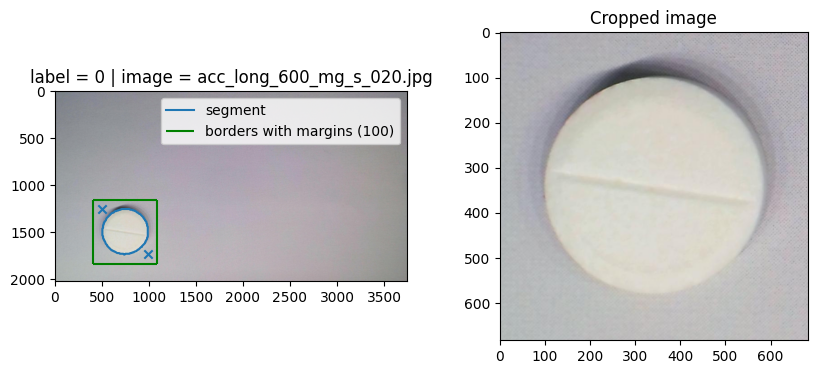

In [ ]:
# возьмем образец изображения и его описания
# - фото        - acc_long_600_mg_s_020.jpg
# - описание    - acc_long_600_mg_s_020.txt

from PIL import Image
import matplotlib.pyplot as plt
import pathlib as path
import numpy as np

# read image
data_path = path.Path('data/dataset/sample')
image_name = 'acc_long_600_mg_s_020'
image_path = data_path / (image_name + '.jpg')
image = Image.open(image_path)

# read label and segment points
with open(data_path / (image_name + '.txt')) as f:
    metadata = f.readline()

# plot image
plot_image_from_dataset(image, image_name, metadata)
